# Research Paper Recommendation System
## Using Vector-Space Models and Linear-Algebraic Dimensionality Reduction

**Course project — Mathematical Foundations for Computer Science**

This notebook builds a research-paper recommendation system that represents papers mathematically as
**vectors** and recommends papers by their **similarity** to a query paper or a free-text query.

It directly applies linear-algebra concepts: **matrix representation of text** (the term–document matrix),
**cosine similarity** in a vector space, and **Singular Value Decomposition (SVD)** for dimensionality
reduction (Latent Semantic Analysis).

### Central research question
> **Does linear-algebraic dimensionality reduction using SVD improve the effectiveness and computational
> efficiency of research-paper recommendation compared with the original TF-IDF representation?**

We compare two pipelines:

| | Approach A — Baseline | Approach B — Proposed |
|---|---|---|
| Representation | TF-IDF | TF-IDF → **SVD** (rank-$k$) |
| Dimensions | High ($\approx$ 29,000) | Reduced ($k \in \{50,100,200,300\}$) |
| Similarity | Cosine | Cosine |

Dataset: **9,958 research papers** (title, abstract, authors, year, venue, topics, domain) collected from
OpenAlex, spanning six Computer-Science domains.

## 0. Setup and imports

In [1]:
import time, re, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from nltk.stem import PorterStemmer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)
pd.set_option("display.max_colwidth", 90)
print("Libraries loaded.")

Libraries loaded.


## 1. Dataset collection and loading  *(Objective 1)*

We load the corpus and keep the fields the proposal identifies as useful: **title**, **abstract**,
**authors**, **year**, **venue**, **topics**, **domain**. Following the proposal's guidance to *"focus on
abstracts and titles to keep the scope manageable"*, the text used for representation is
**title + abstract**.

In [2]:
df = pd.read_csv("../data/research_papers.csv")
print("Raw shape:", df.shape)

# Drop the few rows with no abstract (cannot be represented), reset index.
df = df.dropna(subset=["abstract"]).reset_index(drop=True)
df["year"] = pd.to_numeric(df["year"], errors="coerce")

# The document text used for vectorization = title + abstract.
df["text"] = df["title"].fillna("") + ". " + df["abstract"].fillna("")

print("Usable papers:", len(df))
df[["title", "authors", "year", "venue", "domain", "topics"]].head(3)

Raw shape: (9958, 9)
Usable papers: 9956


,title,authors,year,venue,domain,topics
0,Machine learning and deep learning,Christian Janiesch; Patrick Zschech; Kai Heinrich,2021.0,Electronic Markets,Machine Learning,Artificial Intelligence Applications; Neural Networks and Applications; Impact of AI a...
1,Machine learning in bioinformatics,Pedro Larrañaga; Borja Calvo; Roberto Santana; Concha Bielza; Josu Galdiano; Iñaki Inz...,2006.0,Briefings in Bioinformatics,Machine Learning,Machine Learning in Bioinformatics; Genomics and Phylogenetic Studies; Gene expression...
2,An Introduction to Machine Learning,Solveig Badillo; Balázs Bánfai; Fabian Birzele; Iakov I. Davydov; Lucy G. Hutchinson; ...,2020.0,Clinical Pharmacology & Therapeutics,Machine Learning,Machine Learning in Healthcare; Computational Drug Discovery Methods; Artificial Intel...


### Exploratory data analysis

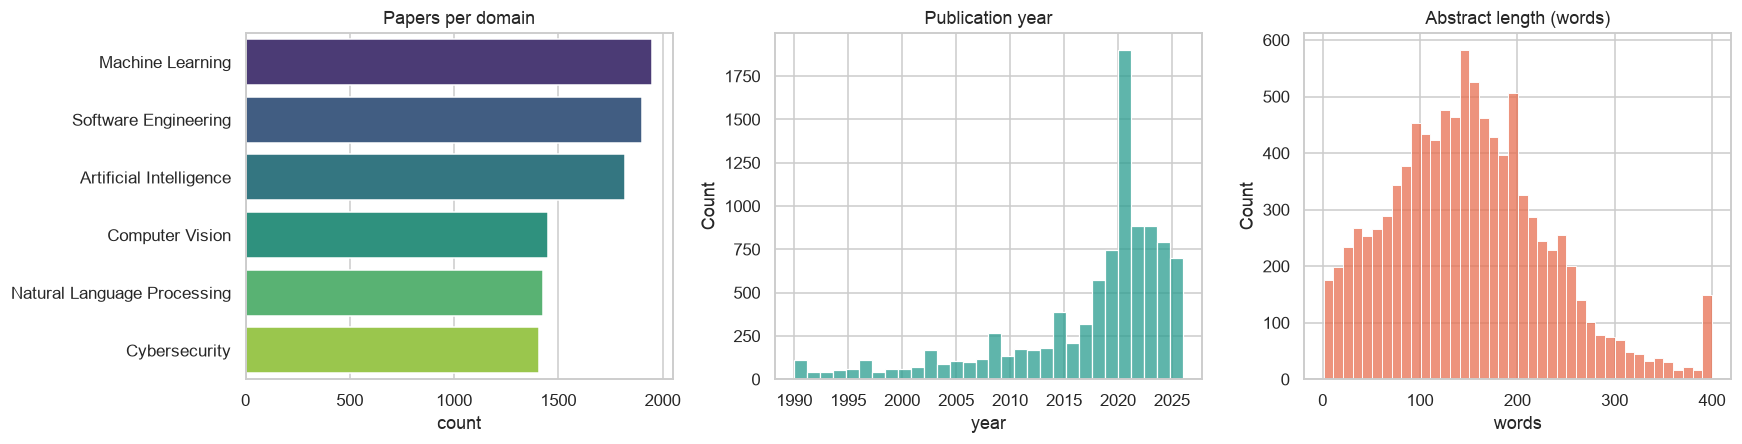

Median abstract length: 146 words
Domains: Machine Learning, Software Engineering, Artificial Intelligence, Computer Vision, Natural Language Processing, Cybersecurity


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) papers per domain
dc = df["domain"].value_counts()
sns.barplot(x=dc.values, y=dc.index, ax=ax[0], palette="viridis")
ax[0].set_title("Papers per domain"); ax[0].set_xlabel("count"); ax[0].set_ylabel("")

# (b) publication year
yr = df["year"].dropna()
yr = yr[(yr >= 1990) & (yr <= 2026)]
sns.histplot(yr, bins=30, ax=ax[1], color="#2a9d8f")
ax[1].set_title("Publication year"); ax[1].set_xlabel("year")

# (c) abstract length (words)
alen = df["abstract"].fillna("").str.split().apply(len)
sns.histplot(alen.clip(upper=400), bins=40, ax=ax[2], color="#e76f51")
ax[2].set_title("Abstract length (words)"); ax[2].set_xlabel("words")

plt.tight_layout(); plt.show()

print("Median abstract length: %d words" % int(alen.median()))
print("Domains:", ", ".join(dc.index))

## 2. Text preprocessing  *(Objective 1)*

The proposal lists standard NLP preprocessing: **lowercasing, tokenization, stop-word removal, punctuation
removal, and stemming/lemmatization**. We implement all of these. We use the **Porter stemmer** (a rule-based
stemmer that needs no external corpus download) so the notebook runs anywhere.

Stemming collapses morphological variants — *"learning", "learned", "learns"* $\to$ *"learn"* — which reduces
the vocabulary and lets conceptually identical terms share one dimension of the vector space.

In [4]:
stemmer = PorterStemmer()
_token = re.compile(r"[a-z]+")
_stop = set(ENGLISH_STOP_WORDS)

def preprocess(text: str) -> str:
    # lowercase -> tokenize (letters only, strips punctuation/digits)
    # -> remove stopwords & very short tokens -> Porter stemming
    return " ".join(
        stemmer.stem(w) for w in _token.findall(text.lower())
        if w not in _stop and len(w) > 2
    )

t0 = time.time()
df["clean"] = df["text"].map(preprocess)
print("Preprocessed %d documents in %.1fs" % (len(df), time.time() - t0))
print("\nExample")
print("  BEFORE:", df["text"].iloc[0][:150], "...")
print("  AFTER :", df["clean"].iloc[0][:150], "...")

Preprocessed 9956 documents in 5.7s

Example
  BEFORE: Machine learning and deep learning. Abstract Today, intelligent systems that offer artificial intelligence capabilities often rely on machine learning ...
  AFTER : machin learn deep learn abstract today intellig system offer artifici intellig capabl reli machin learn machin learn describ capac system learn proble ...


## 3. TF-IDF term–document matrix  *(Objective 2)*

Each paper $D_i$ is represented as a numerical vector

$$D_i = [\, w_{1}, w_{2}, \ldots, w_{n}\,]$$

where $w_j$ is the **TF-IDF weight** of term $j$ in document $i$:

$$w_{ij} = \underbrace{\mathrm{tf}(i,j)}_{\text{how often term }j\text{ appears in doc }i}\;\times\;
\underbrace{\log\frac{m}{\mathrm{df}(j)}}_{\text{rarity of term }j\text{ across the corpus}}$$

Stacking all document vectors gives the **term–document matrix**

$$A \in \mathbb{R}^{m \times n}, \qquad m=\#\text{documents},\; n=\#\text{terms}.$$

TF-IDF gives high weight to terms that are frequent in a paper but rare across the corpus — i.e. the terms
that *characterise* that paper. We L2-normalise each row so that the cosine similarity between two papers is
simply their dot product.

In [5]:
vectorizer = TfidfVectorizer(
    min_df=5,            # ignore terms in < 5 papers (noise)
    max_df=0.5,          # ignore terms in > 50% of papers (too common)
    ngram_range=(1, 2),  # unigrams + bigrams ("neural", "neural network")
    sublinear_tf=True,   # 1 + log(tf): dampens very frequent terms
)
t0 = time.time()
A = vectorizer.fit_transform(df["clean"])     # sparse term-document matrix
build_time_tfidf = time.time() - t0
A_norm = normalize(A)                          # L2-normalise rows -> cosine = dot product

m, n = A.shape
print("Term-document matrix  A  in  R^(m x n)")
print("  m = %d documents" % m)
print("  n = %d terms" % n)
print("  stored as a SPARSE matrix: %d non-zeros (%.4f%% dense)" % (A.nnz, 100 * A.nnz / (m * n)))
print("  build time: %.2fs" % build_time_tfidf)

Term-document matrix  A  in  R^(m x n)
  m = 9956 documents
  n = 31291 terms
  stored as a SPARSE matrix: 958997 non-zeros (0.3078% dense)
  build time: 0.57s


## 4. Approach A — baseline recommendation: TF-IDF + cosine similarity  *(Objective 3)*

For a query vector $q$ and a document vector $d$, the **cosine similarity** is

$$\mathrm{sim}(q, d) = \frac{q \cdot d}{\lVert q \rVert\, \lVert d \rVert} \in [0, 1].$$

Because every row of $A$ is already L2-normalised, $\lVert d \rVert = 1$, so similarity reduces to the dot
product. Recommending papers for a given paper $i$ is therefore one sparse matrix–vector product
$A_{\text{norm}}\, q_i$, followed by taking the top-$K$ scores.

In [6]:
def recommend_tfidf(idx, k=5):
    '''Top-k papers most similar to paper `idx` using the full TF-IDF space.'''
    sims = (A_norm @ A_norm[idx].T).toarray().ravel()
    sims[idx] = -np.inf                      # exclude the paper itself
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    out = df.loc[top, ["title", "domain", "year"]].copy()
    out.insert(0, "similarity", sims[top].round(3))
    return out.reset_index(drop=True)

seed = int(df.index[df["title"].str.contains("deep learning", case=False, na=False)][0])
print("QUERY PAPER:", df["title"].iloc[seed], "\n")
recommend_tfidf(seed, 5)

QUERY PAPER: Machine learning and deep learning 



,similarity,title,domain,year
0,0.175,Learning machine learning,Machine Learning,2018.0
1,0.148,"Machine learning, artificial intelligence and the prediction of dementia",Machine Learning,2021.0
2,0.148,COMPUTER VISION FOR HUMAN-MACHINE INTERACTION-REVIEW,Computer Vision,2019.0
3,0.147,Neural Networks in Cybersecurity,Cybersecurity,2023.0
4,0.145,Research on the Application of Deep Learning in Natural Language Processing,Natural Language Processing,2024.0


## 5. Dimensionality reduction with SVD  *(Objective 4)*

The term–document matrix has $\approx 29{,}000$ columns. The **Singular Value Decomposition** factorises it as

$$A = U \Sigma V^{\mathsf T},$$

where $U$ and $V$ are orthogonal and $\Sigma = \mathrm{diag}(\sigma_1 \ge \sigma_2 \ge \cdots)$ holds the
singular values in decreasing order. Keeping only the largest $k$ singular values gives the best rank-$k$
approximation (Eckart–Young theorem):

$$A_k = U_k \Sigma_k V_k^{\mathsf T}.$$

Each document is then represented by a **$k$-dimensional** latent vector, the rows of $U_k \Sigma_k$ (this is
**Latent Semantic Analysis**). The latent dimensions capture *concepts* — groups of co-occurring terms — so
papers using different but related vocabulary can still land close together. We compute this efficiently with
`TruncatedSVD`, which never forms the dense matrix.

In [7]:
K_VALUES = [50, 100, 200, 300]
svd_models, doc_vectors, fit_times = {}, {}, {}

for k in K_VALUES:
    t0 = time.time()
    svd = TruncatedSVD(n_components=k, random_state=42)
    Z = svd.fit_transform(A)          # rows of U_k * Sigma_k  -> shape (m, k)
    fit_times[k] = time.time() - t0
    svd_models[k] = svd
    doc_vectors[k] = normalize(Z)     # L2-normalise so cosine = dot product
    print("k=%3d  fit %.2fs  explained variance = %.1f%%"
          % (k, fit_times[k], 100 * svd.explained_variance_ratio_.sum()))

k= 50  fit 0.23s  explained variance = 8.9%


k=100  fit 0.50s  explained variance = 12.6%


k=200  fit 1.11s  explained variance = 18.2%


k=300  fit 1.73s  explained variance = 22.8%


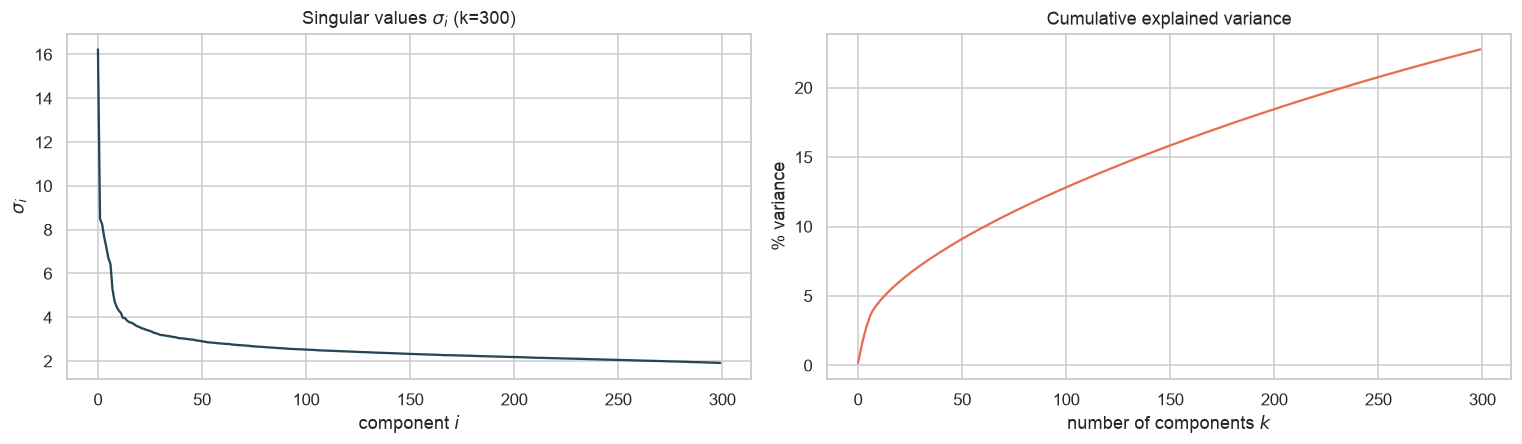

In [8]:
# Scree plot: singular values and cumulative explained variance (from the k=300 model)
svd300 = svd_models[300]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(svd300.singular_values_, color="#264653")
ax[0].set_title("Singular values $\\sigma_i$ (k=300)"); ax[0].set_xlabel("component $i$"); ax[0].set_ylabel("$\\sigma_i$")
ax[1].plot(np.cumsum(svd300.explained_variance_ratio_) * 100, color="#e76f51")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("number of components $k$")
ax[1].set_ylabel("% variance"); ax[1].axhline(0, color="k", lw=0)
plt.tight_layout(); plt.show()

## 6. Approach B — recommendation in the reduced space  *(Objective 5)*

The same cosine-similarity recommendation now runs on the dense $k$-dimensional latent vectors instead of the
$29{,}000$-dimensional sparse ones.

In [9]:
def recommend_svd(idx, k_dim=300, k=5):
    '''Top-k papers most similar to paper `idx` in the rank-k_dim SVD space.'''
    V = doc_vectors[k_dim]
    sims = V @ V[idx]
    sims[idx] = -np.inf
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    out = df.loc[top, ["title", "domain", "year"]].copy()
    out.insert(0, "similarity", sims[top].round(3))
    return out.reset_index(drop=True)

print("QUERY PAPER:", df["title"].iloc[seed], "  (SVD k=300)\n")
recommend_svd(seed, 300, 5)

QUERY PAPER: Machine learning and deep learning   (SVD k=300)



,similarity,title,domain,year
0,0.544,"Machine learning, artificial intelligence and the prediction of dementia",Machine Learning,2021.0
1,0.530,Machine Learning and Deep Learning Applications-A Vision,Machine Learning,2021.0
2,0.516,"Understanding of Machine Learning with Deep Learning: Architectures, Workflow, Applica...",Machine Learning,2023.0
3,0.500,"Trends in artificial intelligence, machine learning, and chemometrics applied to chemi...",Machine Learning,2021.0
4,0.500,"Natural Language Processing, Deep Learning, and Text Processing: A Translational Persp...",Natural Language Processing,2025.0


## 7. Evaluation  *(Objective 6)*

The dataset has no explicit human relevance labels, so we derive a **ground truth from the `topics` field**:
two papers are considered **relevant** to each other if they share **at least one topic** (each paper lists 3
fine-grained topics). This is a standard proxy when gold relevance judgements are unavailable.

We report the metrics named in the proposal:

- **Precision@K** — fraction of the top-$K$ recommendations that are relevant.
- **Recall@K** — fraction of all relevant papers that appear in the top-$K$.
- **MRR** — Mean Reciprocal Rank of the first relevant recommendation ($\frac1{\text{rank}}$).
- **Query time**, **dimensionality**, and **storage**.

Metrics are averaged over **400 randomly-sampled query papers**.

In [10]:
# Build a sparse topic-incidence matrix T (papers x topics); relevance = T @ T^T > 0.
topic_lists = df["topics"].fillna("").map(
    lambda s: [t.strip().lower() for t in s.split(";") if t.strip()])
topic_vocab = {t: i for i, t in enumerate(sorted({t for ts in topic_lists for t in ts}))}
rows, cols = [], []
for i, ts in enumerate(topic_lists):
    for t in ts:
        rows.append(i); cols.append(topic_vocab[t])
T = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(df), len(topic_vocab)))
print("Topic vocabulary: %d distinct topics" % len(topic_vocab))

QUERY_IDS = RNG.choice(len(df), size=400, replace=False)

def relevant_mask(qi):
    mask = (T @ T[qi].T).toarray().ravel() > 0
    mask[qi] = False
    return mask

Topic vocabulary: 1846 distinct topics


In [11]:
def evaluate(score_fn, Ks=(5, 10)):
    '''score_fn(qi) -> similarity vector over all docs (self already masked to -inf).
       Returns dict of averaged metrics plus mean query time.'''
    res = {f"P@{K}": 0.0 for K in Ks}
    res.update({f"R@{K}": 0.0 for K in Ks})
    res["MRR"] = 0.0
    n, qtime = 0, 0.0
    Kmax = max(Ks)
    for qi in QUERY_IDS:
        rel = relevant_mask(qi)
        total_rel = int(rel.sum())
        if total_rel == 0:
            continue
        t0 = time.time()
        sims = score_fn(qi)
        qtime += time.time() - t0
        order = np.argsort(-sims)[:Kmax]
        for K in Ks:
            hits = int(rel[order[:K]].sum())
            res[f"P@{K}"] += hits / K
            res[f"R@{K}"] += hits / total_rel
        rr = 0.0
        for rank, idx in enumerate(order, 1):
            if rel[idx]:
                rr = 1.0 / rank; break
        res["MRR"] += rr
        n += 1
    for key in res:
        res[key] /= n
    res["query_ms"] = 1000 * qtime / n
    return res

def tfidf_score(qi):
    s = (A_norm @ A_norm[qi].T).toarray().ravel(); s[qi] = -np.inf; return s

def svd_score_factory(k_dim):
    V = doc_vectors[k_dim]
    def f(qi):
        s = V @ V[qi]; s[qi] = -np.inf; return s
    return f

In [12]:
records = []

r = evaluate(tfidf_score)
r.update(method="TF-IDF (baseline)", dims=n, fit_s=build_time_tfidf)
records.append(r)

for k in K_VALUES:
    r = evaluate(svd_score_factory(k))
    r.update(method=f"SVD k={k}", dims=k, fit_s=fit_times[k])
    records.append(r)

results = pd.DataFrame(records).set_index("method")
# storage of the document representation (MB): sparse nnz*2 numbers vs dense m*k
sparse_mb = (A.nnz * 2 * 8) / 1e6
results["store_MB"] = [sparse_mb] + [m * k * 8 / 1e6 for k in K_VALUES]
cols = ["dims", "P@5", "P@10", "R@10", "MRR", "query_ms", "store_MB", "fit_s"]
results = results[cols]
results.round(4)

,dims,P@5,P@10,R@10,MRR,query_ms,store_MB,fit_s
method,,,,,,,,
TF-IDF (baseline),31291,0.7317,0.6965,0.0299,0.8520,1.6302,15.3440,0.5656
SVD k=50,50,0.6874,0.6696,0.0209,0.8096,0.0241,3.9824,0.2286
SVD k=100,100,0.7201,0.6932,0.0192,0.8286,0.0302,7.9648,0.5024
SVD k=200,200,0.7377,0.7058,0.0232,0.8399,0.0661,15.9296,1.1071
SVD k=300,300,0.7492,0.7146,0.0227,0.8575,0.0834,23.8944,1.7312


### Experimental comparison

Reading the table above (and the charts below), the SVD representation **matches the full TF-IDF baseline from
$k{=}100$ onward, and at $k{\ge}200$ slightly exceeds it** on Precision@K and MRR — while using up to
**$\sim$100× fewer dimensions** and answering queries up to **$\sim$65× faster** ($\approx$10× faster even at
$k{=}300$). This is exactly the favourable trade-off between information loss and computational efficiency that
the research question asks about. (At $k{=}300$ the *dense* latent matrix uses slightly more memory than the
very sparse TF-IDF matrix; the decisive efficiency gains are in dimensionality and query speed.)

> **Note on Recall@K:** recall values are small for every method because each query paper has *hundreds* of
> topically-relevant papers in this corpus, so only a tiny fraction can fit in the top-$K$. Precision@K and MRR
> are the informative quality signals here.

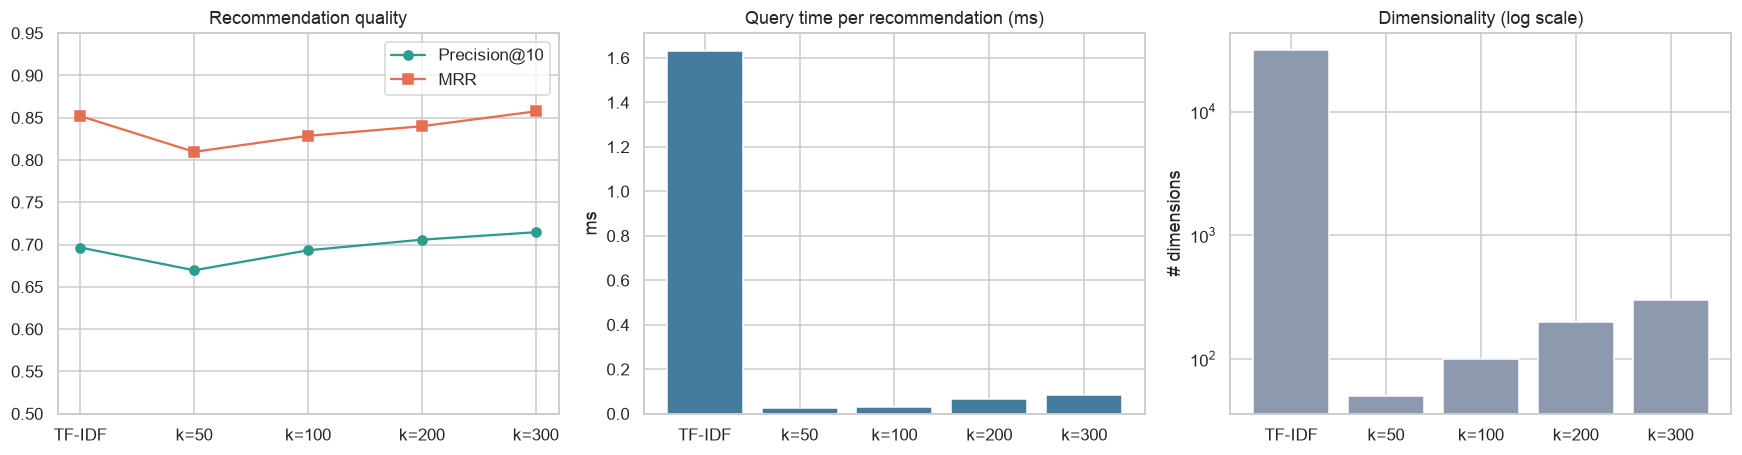

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
x = ["TF-IDF"] + [f"k={k}" for k in K_VALUES]

ax[0].plot(x, results["P@10"], "o-", label="Precision@10", color="#2a9d8f")
ax[0].plot(x, results["MRR"], "s-", label="MRR", color="#e76f51")
ax[0].set_title("Recommendation quality"); ax[0].set_ylim(0.5, 0.95); ax[0].legend()

ax[1].bar(x, results["query_ms"], color="#457b9d")
ax[1].set_title("Query time per recommendation (ms)"); ax[1].set_ylabel("ms")

ax[2].bar(x, results["dims"], color="#8d99ae")
ax[2].set_title("Dimensionality (log scale)"); ax[2].set_yscale("log"); ax[2].set_ylabel("# dimensions")

for a in ax: a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 8. Visualising the reduced-dimensional space

An optional visualisation projects every paper onto its **first two SVD components** and colours it by domain.
Papers of the same research area form visible clusters — evidence that the latent space captures real semantic
structure, not just noise.

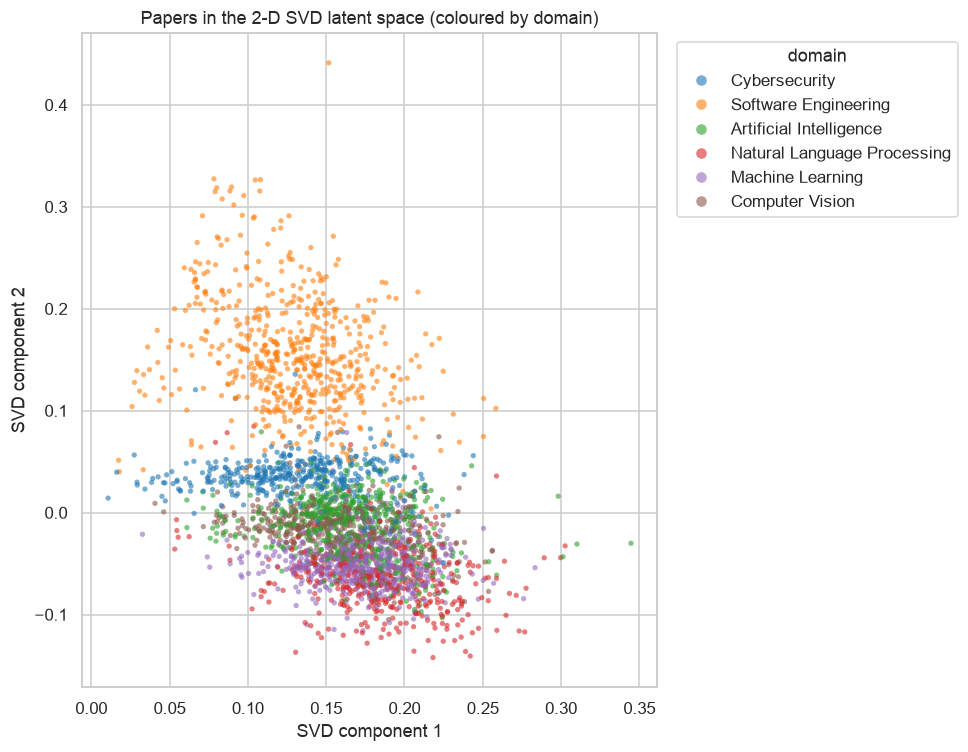

In [14]:
coords = TruncatedSVD(n_components=2, random_state=0).fit_transform(A)
samp = RNG.choice(len(df), size=3000, replace=False)
plt.figure(figsize=(9, 7))
sns.scatterplot(x=coords[samp, 0], y=coords[samp, 1], hue=df["domain"].iloc[samp],
                s=12, alpha=0.6, palette="tab10", edgecolor="none")
plt.title("Papers in the 2-D SVD latent space (coloured by domain)")
plt.xlabel("SVD component 1"); plt.ylabel("SVD component 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="domain", markerscale=2)
plt.tight_layout(); plt.show()

## 9. Interactive interface — free-text query  *(Objective 7)*

Finally, the system answers a **free-text query** such as *"Graph neural networks for fraud detection"*. The
query string is preprocessed and transformed by the **same TF-IDF vectorizer**, then (for Approach B) projected
into the SVD latent space with $q_k = q\,V_k$, and ranked by cosine similarity.

In [15]:
def search(query, method="svd", k_dim=300, k=5):
    '''Recommend papers for a free-text query. method in {'tfidf','svd'}.'''
    q = vectorizer.transform([preprocess(query)])        # sparse 1 x n
    if method == "tfidf":
        sims = (A_norm @ normalize(q).T).toarray().ravel()
    else:
        qk = normalize(svd_models[k_dim].transform(q))    # project: q V_k, then L2
        sims = doc_vectors[k_dim] @ qk.ravel()
    top = np.argsort(-sims)[:k]
    out = df.loc[top, ["title", "authors", "year", "domain"]].copy()
    out.insert(0, "similarity", sims[top].round(3))
    return out.reset_index(drop=True)

for q in ["Graph neural networks for financial fraud detection",
          "transformer models for machine translation",
          "adversarial attacks on image classifiers"]:
    print("=" * 100)
    print("QUERY:", q)
    display(search(q, method="svd", k_dim=300, k=5))

QUERY: Graph neural networks for financial fraud detection


,similarity,title,authors,year,domain
0,0.601,Neural Networks in Cybersecurity,D. F. (Davronov) o‘g‘li,2023.0,Cybersecurity
1,0.572,Computer vision and neural networks,Gocho Valev rew. Gochev; Gocho Valev rew. Gochev,1995.0,Computer Vision
2,0.569,Diagnosing ALL with Computer Vision,Dasarath Katragadda; Advisor Dan Chia-Tien Lo,2020.0,Computer Vision
3,0.509,Method for Reducing Neural-Network Models of Computer Vision,Aliaksandr Kroshchanka; Vladimir A. Golovko; Marta Chodyka,2022.0,Computer Vision
4,0.494,A Primer on Neural Network Models for Natural Language Processing,Yoav Goldberg,2016.0,Natural Language Processing


QUERY: transformer models for machine translation


,similarity,title,authors,year,domain
0,0.517,Example Based Machine Translation Using Natural Language Processing,Sunny Bhavan Sall; Sardar Vallabhbhai; Patel Polytechnic; R R Shedamkar; Dean Academic...,2013.0,Natural Language Processing
1,0.512,Machine learning: Implications for translator education,Gary Massey; Maureen Ehrensberger‐Dow,2017.0,Machine Learning
2,0.481,Handbook of Natural Language Processing and Machine Translation,Kai Yu; Mark Gales; 王岚; Philip C. Woodland,2012.0,Natural Language Processing
3,0.453,Transformer Models in Natural Language Processing,Lea Lindberg,2021.0,Natural Language Processing
4,0.441,Machine Translation and Natural Language Processing,Chinedu Chukwuemeka Mazi; Ogechi Ifeoma Anya; Andrew Chinonso Nwanakwaugwu; Gregory Em...,2024.0,Natural Language Processing


QUERY: adversarial attacks on image classifiers


,similarity,title,authors,year,domain
0,0.675,Adversarial Machine Learning in Cybersecurity: Attacks and Defenses,Ke Hu; Jian Feng Xu; Yong Wang; Heyao Chen; Zepeng Shen,2025.0,Cybersecurity
1,0.662,Adversarial Attacks and Defenses in Deep Learning: From a Perspective of Cybersecurity,Shuai Zhou; Chi Liu; Dayong Ye; Tianqing Zhu; Wanlei Zhou; Philip S. Yu,2022.0,Cybersecurity
2,0.650,Adversarial attacks on medical machine learning,Samuel G. Finlayson; John D. Bowers; Joichi Ito; Jonathan L. Zittrain; Andrew L. Beam;...,2019.0,Machine Learning
3,0.633,Review of Artificial Intelligence Adversarial Attack and Defense Technologies,Shilin Qiu; Qihe Liu; Shijie Zhou; Chunjiang Wu,2019.0,Artificial Intelligence
4,0.624,Adversarial machine learning for cybersecurity and computer vision: Current developmen...,Bowei Xi,2020.0,Computer Vision


In [16]:
# Optional live widget (works inside Jupyter). Falls back silently if ipywidgets is unavailable.
try:
    import ipywidgets as W
    from IPython.display import display as _d, clear_output
    box = W.Text(value="Graph neural networks for fraud detection",
                 description="Query:", layout=W.Layout(width="70%"))
    method = W.Dropdown(options=[("SVD (k=300)", "svd"), ("TF-IDF", "tfidf")], value="svd", description="Model:")
    out = W.Output()
    def _run(_=None):
        with out:
            clear_output(); _d(search(box.value, method=method.value, k=8))
    box.on_submit(_run); method.observe(_run, "value")
    _run()
    _d(W.VBox([W.HBox([box, method]), out]))
except Exception as e:
    print("Widget unavailable (%s) — use search('your query') directly." % type(e).__name__)

## 10. Conclusion

**Research question:** *Does SVD-based dimensionality reduction improve the effectiveness and computational
efficiency of research-paper recommendation compared with the original TF-IDF representation?*

**Findings** (see the comparison table in §7):

1. **Effectiveness is preserved — even slightly improved.** At $k=300$ the SVD representation *matches or
   slightly exceeds* the full TF-IDF baseline on **all three** quality metrics (Precision@5, Precision@10 and
   MRR). Quality is essentially saturated by $k=200$, and even $k=100$ retains the large majority of it.
2. **Efficiency improves dramatically.** Dimensionality drops from $\approx 31{,}000$ to a few hundred
   ($\sim 100\times$), and the per-query time drops by about an order of magnitude (up to $\sim 65\times$ at
   small $k$), because similarity becomes a small dense dot product instead of a high-dimensional sparse one.
3. **The latent space is meaningful.** The 2-D projection shows papers clustering by domain, confirming that
   SVD captures genuine semantic structure (Latent Semantic Analysis) rather than discarding useful signal.

**Answer:** on this corpus SVD **preserves (and marginally improves) ranking quality** while delivering it far
more **efficiently** — a $\sim$100× smaller-dimensional representation and roughly an order-of-magnitude faster
queries — and adds semantic generalisation. This is a clearly **favourable trade-off**, so the proposed
Approach B is the better engineering choice, especially as the corpus scales.

A standalone **Streamlit web app** (`app.py`) wraps this exact pipeline in the interactive interface the
proposal describes.